# Assignment 3 - Step 1: Data Preparation

In this notebook I prepare the Project Gutenberg dataset for the later models.

The goal of this step is to build a clean and manageable dataset for text classification.  
I do not use the full corpus because the assignment explicitly warns that the dataset can become too large for normal hardware. I first create a smaller but still representative subset.

### Design choices and limitations

This preprocessing pipeline was designed to create a manageable multi-label text classification dataset from Project Gutenberg books.

- **Bookshelves were used as labels instead of Subjects** because they are less noisy and more consistent across books.
- **The number of books and chunks per book was limited** to keep the dataset feasible for local training on my hardware.
- **Texts were split into overlapping chunks of 256 words** so that each training sample remains short enough for neural models while still preserving local context.
- **An overlap of 32 words was used** to reduce information loss at chunk boundaries.
- **A train/validation/test split was applied at book level** to avoid leakage between chunks from the same book.
- **Matching metadata to text files by title is not perfect** and may fail in edge cases where filenames and titles differ.

This approach is a practical approximation

Despite these limitations, the resulting dataset is suitable for comparing multiple classification approaches in the scope of this assignment.

In [82]:
import json
import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

In [83]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = Path.cwd()

OUT_DIR = PROJECT_ROOT / "data/processed/"

CSV_PATH = PROJECT_ROOT / "data/raw/pg_catalog.csv"
TEXT_DIR = PROJECT_ROOT / "data/raw/project Gutenberg"

MAX_LABELS = 10
MIN_BOOKS_PER_LABEL = 80
MAX_BOOKS = 1200

MIN_BOOK_WORDS = 800
CHUNK_SIZE = 256
CHUNK_OVERLAP = 32
MAX_CHUNKS_PER_BOOK = 16

## Load metadata and select labels

I first load the metadata file and filter it to English texts only.  
Then I select labels from the **Bookshelves** column.

I use Bookshelves instead of Subjects because they are usually less noisy and more suitable for a first multi-label classification task. I also keep only labels that occur often enough, because very rare labels would make training unstable on a limited dataset.

In [84]:
df = pd.read_csv(CSV_PATH, low_memory=False)

df = df.rename(columns={
    "Text#": "text_id",
    "Title": "title",
    "Authors": "authors",
    "Language": "language",
    "Type": "type",
    "Bookshelves": "bookshelves",
    "Subjects": "subjects"
})

print(df.shape)
df.head()

(77070, 9)


,text_id,type,Issued,title,language,authors,subjects,LoCC,bookshelves
0,1,Text,1971-12-01,The Declaration of Independence of the United ...,en,"Jefferson, Thomas, 1743-1826","United States -- History -- Revolution, 1775-1...",E201; JK,Politics; American Revolutionary War; United S...
1,2,Text,1972-12-01,The United States Bill of Rights\r\nThe Ten Or...,en,United States,Civil rights -- United States -- Sources; Unit...,JK; KF,Politics; American Revolutionary War; United S...
2,3,Text,1973-11-01,John F. Kennedy's Inaugural Address,en,"Kennedy, John F. (John Fitzgerald), 1917-1963",United States -- Foreign relations -- 1961-196...,E838,"Category: Essays, Letters & Speeches; Category..."
3,4,Text,1973-11-01,Lincoln's Gettysburg Address\r\nGiven November...,en,"Lincoln, Abraham, 1809-1865",Consecration of cemeteries -- Pennsylvania -- ...,E456,"US Civil War; Category: Essays, Letters & Spee..."
4,5,Text,1975-12-01,The United States Constitution,en,United States,United States -- Politics and government -- 17...,JK; KF,United States; Politics; American Revolutionar...


In [85]:
df = df[df["language"].fillna("").str.contains("en", case=False)].copy()
df = df[df["type"].fillna("").str.lower() == "text"].copy()

def split_labels(x):
    if pd.isna(x):
        return []
    parts = str(x).split(";")
    parts = [p.strip() for p in parts if p.strip()]
    return parts

df["labels"] = df["bookshelves"].apply(split_labels)
df = df[df["labels"].map(len) > 0].copy()

print(df.shape)
df[["text_id", "title", "labels"]].head()

(59618, 10)


,text_id,title,labels
0,1,The Declaration of Independence of the United ...,"[Politics, American Revolutionary War, United ..."
1,2,The United States Bill of Rights\r\nThe Ten Or...,"[Politics, American Revolutionary War, United ..."
2,3,John F. Kennedy's Inaugural Address,"[Category: Essays, Letters & Speeches, Categor..."
3,4,Lincoln's Gettysburg Address\r\nGiven November...,"[US Civil War, Category: Essays, Letters & Spe..."
4,5,The United States Constitution,"[United States, Politics, American Revolutiona..."


In [86]:
all_labels = {}

for labels in df["labels"]:
    for label in labels:
        all_labels[label] = all_labels.get(label, 0) + 1

label_counts = pd.DataFrame({
    "label": list(all_labels.keys()),
    "count": list(all_labels.values())
}).sort_values("count", ascending=False)

label_counts = label_counts[label_counts["count"] >= MIN_BOOKS_PER_LABEL]
selected_labels = label_counts.head(MAX_LABELS)["label"].tolist()

print(selected_labels)
label_counts.head(20)

['Category: Novels', 'Category: British Literature', 'Category: American Literature', 'Category: Adventure', 'Category: Children & Young Adult Reading', 'Category: Biographies', 'Category: History - Modern (1750+)', 'Category: History - American', 'Category: Essays, Letters & Speeches', 'Category: Humour']


,label,count
18,Category: Novels,18431
19,Category: British Literature,9372
28,Category: American Literature,7524
27,Category: Adventure,7333
17,Category: Children & Young Adult Reading,6323
39,Category: Biographies,5156
5,Category: History - Modern (1750+),5016
4,Category: History - American,4827
3,"Category: Essays, Letters & Speeches",4503
22,Category: Humour,4024


In [87]:
df["labels"] = df["labels"].apply(lambda x: [label for label in x if label in selected_labels])
df = df[df["labels"].map(len) > 0].copy()

print(df.shape)
df[["text_id", "title", "labels"]].head()

(42492, 10)


,text_id,title,labels
0,1,The Declaration of Independence of the United ...,"[Category: Essays, Letters & Speeches, Categor..."
1,2,The United States Bill of Rights\r\nThe Ten Or...,[Category: History - American]
2,3,John F. Kennedy's Inaugural Address,"[Category: Essays, Letters & Speeches, Categor..."
3,4,Lincoln's Gettysburg Address\r\nGiven November...,"[Category: Essays, Letters & Speeches, Categor..."
4,5,The United States Constitution,[Category: History - American]


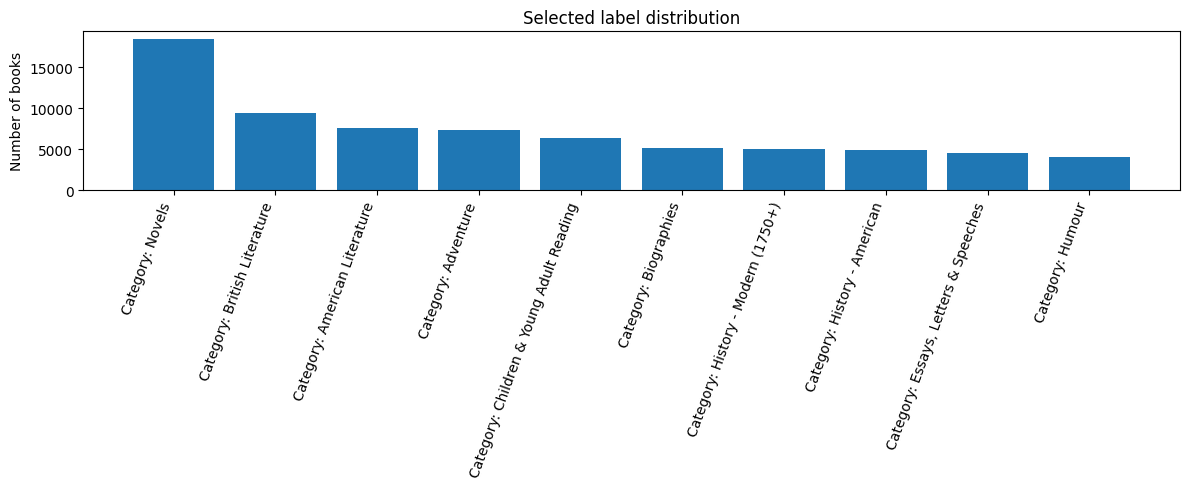

In [88]:
final_counts = {}

for labels in df["labels"]:
    for label in labels:
        final_counts[label] = final_counts.get(label, 0) + 1

plot_df = pd.DataFrame({
    "label": list(final_counts.keys()),
    "count": list(final_counts.values())
}).sort_values("count", ascending=False)

plt.figure(figsize=(12, 5))
plt.bar(plot_df["label"], plot_df["count"])
plt.xticks(rotation=70, ha="right")
plt.title("Selected label distribution")
plt.ylabel("Number of books")
plt.tight_layout()
plt.show()

## Match metadata with text files by title

The raw text files in my dataset are named by book title.

For this reason, I match metadata rows to text files by comparing the book title from the metadata table with the `.txt` filename.  
To make the match more robust, I normalize both titles by lowercasing them and removing punctuation.

I keep only unique matches. If a title has no match or multiple matches, I leave it out at this stage to avoid incorrect file assignments.

Text files are matched to metadata primarily through normalized title comparison.


This is a practical heuristic and may miss or mismatch some books when filenames
differ strongly from metadata titles, but it is sufficient for building a usable
dataset for this assignment.

In [ ]:

def normalize_title(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text.replace("\n", " ").replace("\r", " "))
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

txt_files = list(TEXT_DIR.rglob("*.txt"))

title_map = {}
for path in txt_files:
    key = normalize_title(path.stem)
    if key not in title_map:
        title_map[key] = []
    title_map[key].append(path)

df["title_key"] = df["title"].apply(normalize_title)
df["matches"] = df["title_key"].apply(lambda x: title_map.get(x, []))
df["text_path"] = df["matches"].apply(lambda x: x[0] if len(x) == 1 else None)

matched_df = df[df["text_path"].notna()].copy()
unmatched_df = df[df["text_path"].isna()].copy()

print("Matched:", matched_df.shape)
print("Unmatched:", unmatched_df.shape)

df = matched_df.copy()

Matched: (30016, 13)
Unmatched: (12476, 13)


## Clean raw texts

At this stage I already matched metadata rows to raw `.txt` files.

I preprocess the texts and remove books that are too short after preprocessing. Very short texts are less useful for chunk-based training and would add noise to the dataset.

I also keep track of dropped files and the reason why they were removed.

In [90]:
def clean_gutenberg_text(text):
    text = text.replace("\r\n", "\n").replace("\r", "\n")

    text = re.sub(r"Produced by.*?\n", "", text, flags=re.IGNORECASE)
    text = re.sub(r"\n{3,}", "\n\n", text)
    text = re.sub(r"[ \t]+", " ", text)

    return text.strip()

In [91]:
from tqdm import tqdm

rows = []
dropped = []

total = len(df)
print("Total books:", total)

for _, row in tqdm(df.iterrows(), total=len(df), desc="Processing books"):

    path = row.text_path

    try:
        text = path.read_text(encoding="utf-8")
    except:
        try:
            text = path.read_text(encoding="latin-1")
        except Exception as e:
            dropped.append({
                "text_id": row.text_id,
                "title": row.title,
                "reason": f"read_error: {e}"
            })
            continue

    text = clean_gutenberg_text(text)
    word_count = len(text.split())

    if word_count < MIN_BOOK_WORDS:
        dropped.append({
            "text_id": row.text_id,
            "title": row.title,
            "reason": "too_short"
        })
        continue

    rows.append({
        "book_id": str(row.text_id),
        "text_id": row.text_id,
        "title": row.title,
        "authors": row.authors,
        "labels": row.labels,
        "word_count": word_count,
        "text_path": str(path)
    })

books = pd.DataFrame(rows)
dropped_df = pd.DataFrame(dropped)

print("Books kept:", len(books))
print("Books dropped:", len(dropped_df))

Total books: 30016


Processing books: 100%|██████████| 30016/30016 [13:35<00:00, 36.79it/s] 


Books kept: 29984
Books dropped: 32


In [92]:
if len(books) > MAX_BOOKS:
    books = books.sample(MAX_BOOKS, random_state=SEED).reset_index(drop=True)

print("Books after limiting:", books.shape)

Books after limiting: (1200, 7)


In [93]:
train_books, temp_books = train_test_split(
    books,
    test_size=0.30,
    random_state=SEED
)

val_books, test_books = train_test_split(
    temp_books,
    test_size=0.50,
    random_state=SEED
)

train_books = train_books.copy()
val_books = val_books.copy()
test_books = test_books.copy()

train_books["split"] = "train"
val_books["split"] = "val"
test_books["split"] = "test"

books = pd.concat([train_books, val_books, test_books], ignore_index=True)
books = books.sample(frac=1, random_state=SEED).reset_index(drop=True)

books["split"].value_counts()

split
train    840
test     180
val      180
Name: count, dtype: int64

In [94]:
def make_chunks(text, chunk_size=256, overlap=32):
    words = text.split()
    chunks = []
    step = chunk_size - overlap

    for start in range(0, len(words), step):
        chunk_words = words[start:start + chunk_size]

        if len(chunk_words) < 64:
            break

        chunks.append(" ".join(chunk_words))

    return chunks

In [ ]:
chunk_rows = []

total = len(books)
print("Creating chunks from books:", total)


for i, row in tqdm(books.iterrows(), total=len(books), desc="Chunking book"):

    path = Path(row.text_path)

    try:
        text = path.read_text(encoding="utf-8")
    except:
        text = path.read_text(encoding="latin-1")

    text = clean_gutenberg_text(text)
    chunks = make_chunks(text, CHUNK_SIZE, CHUNK_OVERLAP)

    if len(chunks) > MAX_CHUNKS_PER_BOOK:
        chunks = chunks[:MAX_CHUNKS_PER_BOOK]

    for j, chunk in enumerate(chunks):
        chunk_rows.append({
            "book_id": row.book_id,
            "chunk_id": f"{row.book_id}_{j}",
            "text_id": row.text_id,
            "title": row.title,
            "authors": row.authors,
            "split": row.split,
            "labels": row.labels,
            "text_chunk": chunk,
            "chunk_words": len(chunk.split())
        })

chunks_df = pd.DataFrame(chunk_rows)

print("Chunk dataset shape:", chunks_df.shape)

Creating chunks from books: 1200


Chunking book:   4%|▍         | 1200/30016 [01:04<25:38, 18.73it/s] 

Chunk dataset shape: (18981, 9)


In [96]:
chunks_df["split"].value_counts()

split
train    13302
val       2856
test      2823
Name: count, dtype: int64

## Inspect examples of final chunks

Before saving the prepared dataset, I inspect a few chunk examples manually.

This is a simple sanity check. It helps confirm that the earlier preprocessing and chunking steps produced sensible inputs for the later models.

In [97]:
sample_chunks = chunks_df.sample(3, random_state=SEED)

for _, row in sample_chunks.iterrows():
    print("TITLE:", row["title"])
    print("SPLIT:", row["split"])
    print("LABELS:", row["labels"])
    print("-" * 80)
    print(row["text_chunk"][:1200])
    print("\n" + "=" * 100 + "\n")

TITLE: The seven stairs
SPLIT: train
LABELS: ['Category: Biographies', 'Category: American Literature']
--------------------------------------------------------------------------------
often befell them. It was amazing how he could achieve his devilish ends by the simple incantation, Read your lease. Goodbye. This was his message, whether in the inevitable phone call when you were a day late with the rent, or in answer to your call for help when the fuses in the basement blew or when on a bitter February night the sink broke and the shop began floating away. The sink affair occurred at a point when my business had developed to the extent of a few regular accounts and come to a quiet stalemate. Once these faithful customers had come in, I was through for the month. I could scarcely stand the empty hours waiting for someone to talk with. It was bitter February, cold enough to keep any sensible soul off the streets. I sat before the fire, filled with self-pity, my doomed life stretching h

## Save prepared artifacts

At the end of this step I save the prepared data to disk.

I save both the book-level dataset and the chunk-level dataset. This makes the later notebooks easier to organize and avoids repeating the same preprocessing steps again.

In [98]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

* books_prepared.parquet<br>
This file stores the prepared book-level dataset. It contains the cleaned metadata for each book, such as title, labels, split, and file path.<br>
I save it so I still have the final list of usable books after matching, filtering, and splitting.

* chunks_prepared.parquet<br>
This file stores the prepared chunk-level dataset.<br>
It is the main dataset for the later models, because the models do not use whole books directly. <br>
Saving it means I can load the ready-to-use training data in the next notebook without repeating preprocessing.

* dropped_books.csv<br>
This file stores the books that were removed during preprocessing, together with the reason why they were dropped.<br> 
I save it to keep preprocessing transparent and to show that excluded files were not ignored silently.

In [99]:
books_to_save = books.copy()
chunks_to_save = chunks_df.copy()

books_to_save["labels"] = books_to_save["labels"].apply(json.dumps)
chunks_to_save["labels"] = chunks_to_save["labels"].apply(json.dumps)

books_to_save.to_parquet(OUT_DIR / "books_prepared.parquet", index=False)
chunks_to_save.to_parquet(OUT_DIR / "chunks_prepared.parquet", index=False)
dropped_df.to_csv(OUT_DIR / "dropped_books.csv", index=False)

print("Saved files:")
print(OUT_DIR / "books_prepared.parquet")
print(OUT_DIR / "chunks_prepared.parquet")
print(OUT_DIR / "dropped_books.csv")

Saved files:
c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-3\data\processed\books_prepared.parquet
c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-3\data\processed\chunks_prepared.parquet
c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-3\data\processed\dropped_books.csv


In [100]:
print("Final books shape:", books.shape)
print("Final chunks shape:", chunks_df.shape)

Final books shape: (1200, 8)
Final chunks shape: (18981, 9)


In [101]:
books.head()

,book_id,text_id,title,authors,labels,word_count,text_path,split
0,25698,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",[Category: Children & Young Adult Reading],1949,c:\Users\chupr\Desktop\projects\deep-learning-...,test
1,76585,76585,Just his luck,"Optic, Oliver, 1822-1897; Merrill, Frank T., 1...","[Category: Children & Young Adult Reading, Cat...",79501,c:\Users\chupr\Desktop\projects\deep-learning-...,val
2,4535,4535,Sylvia's Lovers — Volume 2,"Gaskell, Elizabeth Cleghorn, 1810-1865","[Category: Novels, Category: British Literature]",62328,c:\Users\chupr\Desktop\projects\deep-learning-...,train
3,75734,75734,A thoughtless seven,"Le Feuvre, Amy, 1861-1929; Groome, William H. ...","[Category: Children & Young Adult Reading, Cat...",10374,c:\Users\chupr\Desktop\projects\deep-learning-...,train
4,15122,15122,The Little Colonel's Hero,"Johnston, Annie F. (Annie Fellows), 1863-1931;...","[Category: Children & Young Adult Reading, Cat...",57731,c:\Users\chupr\Desktop\projects\deep-learning-...,train


In [102]:
chunks_df.head()

,book_id,chunk_id,text_id,title,authors,split,labels,text_chunk,chunk_words
0,25698,25698_0,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],(This file was produced from images generously...,256
1,25698,25698_1,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],"own good man To his clean hearth, his pipe, an...",256
2,25698,25698_2,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],"rosy children round him press, Eager to share ...",256
3,25698,25698_3,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],Sometimes with beasts compelled to herd; A fis...,256
4,25698,25698_4,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],you name! Think what will best your state amen...,256


## Step 1 conclusion

In this notebook I converted the raw Gutenberg metadata and text files into a clean and manageable dataset for the next steps of the assignment.

The final result of this step is a chunk-based multi-label dataset with cleaned texts, selected labels, a book-level train/validation/test split, and saved artifacts for later notebooks.